In [23]:
# Import all necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve, validation_curve
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from mlxtend.plotting import plot_decision_regions
import scipy.stats as stats

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
%matplotlib inline

# Set random seed for reproducibility
np.random.seed(42)

In [24]:
# Load the dataset
cancer = datasets.load_breast_cancer()
X = cancer.data
y = cancer.target

# Create a DataFrame for exploration
df = pd.DataFrame(X, columns=cancer.feature_names)
df['target'] = y
df['target_name'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(df['target_name'].value_counts())
print("\nFirst 5 rows:")
df.head()

Dataset shape: (569, 30)

Target distribution:
target_name
Benign       357
Malignant    212
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_name
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


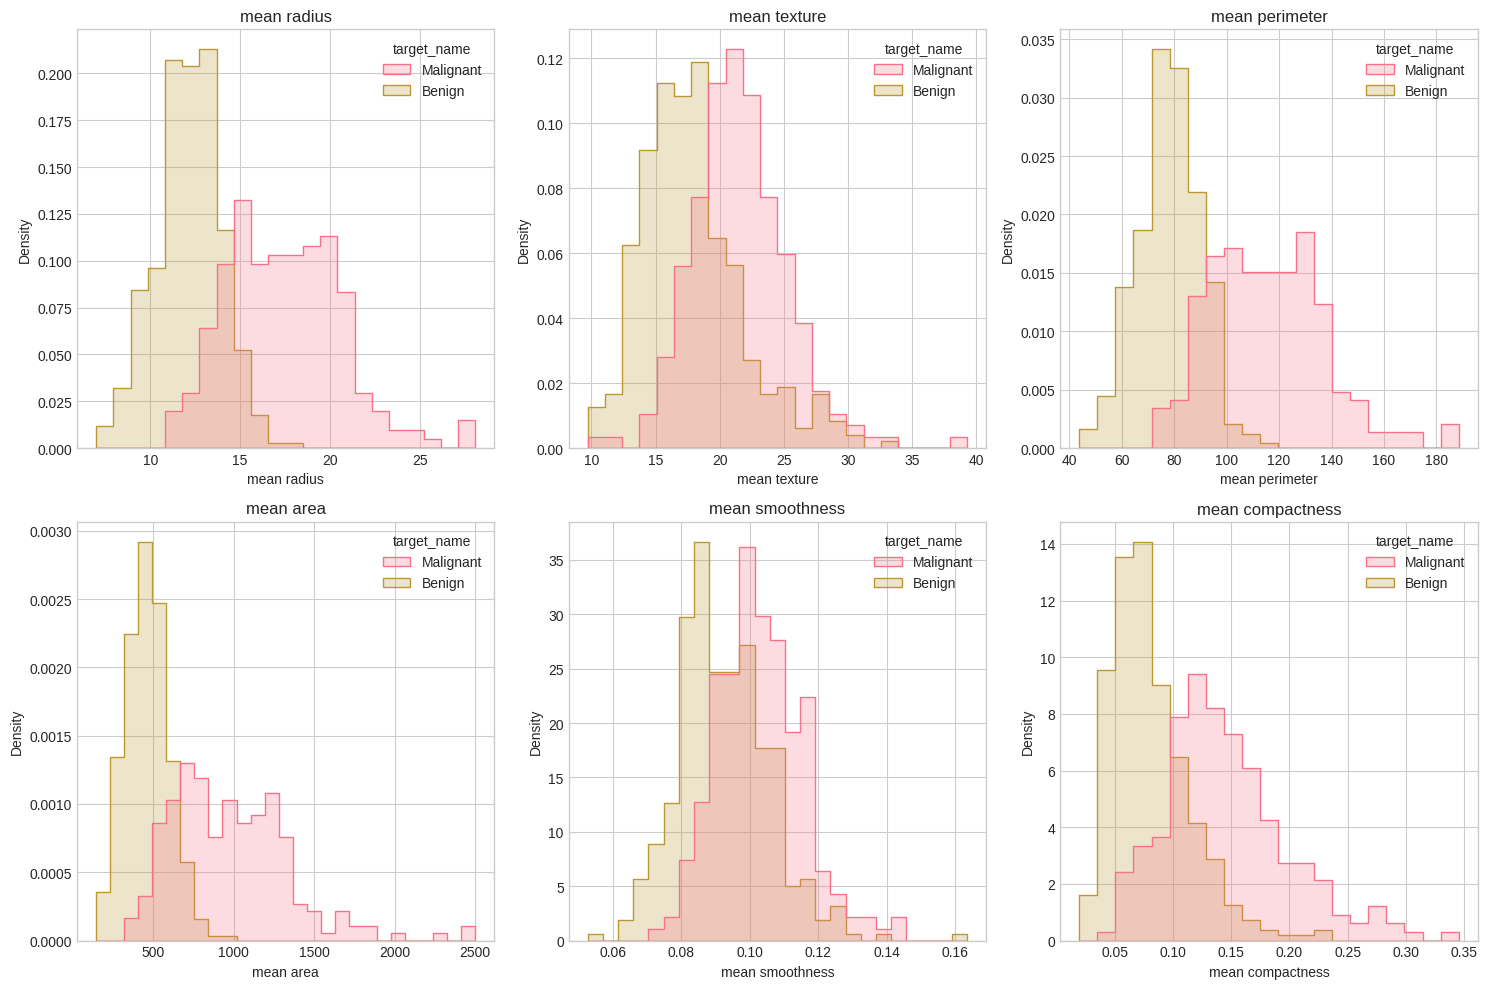

In [25]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(cancer.feature_names[:6]):
    plt.subplot(2, 3, i+1)
    sns.histplot(data=df, x=feature, hue='target_name', element='step', stat='density', common_norm=False)
    plt.title(feature)
plt.tight_layout()
plt.show()

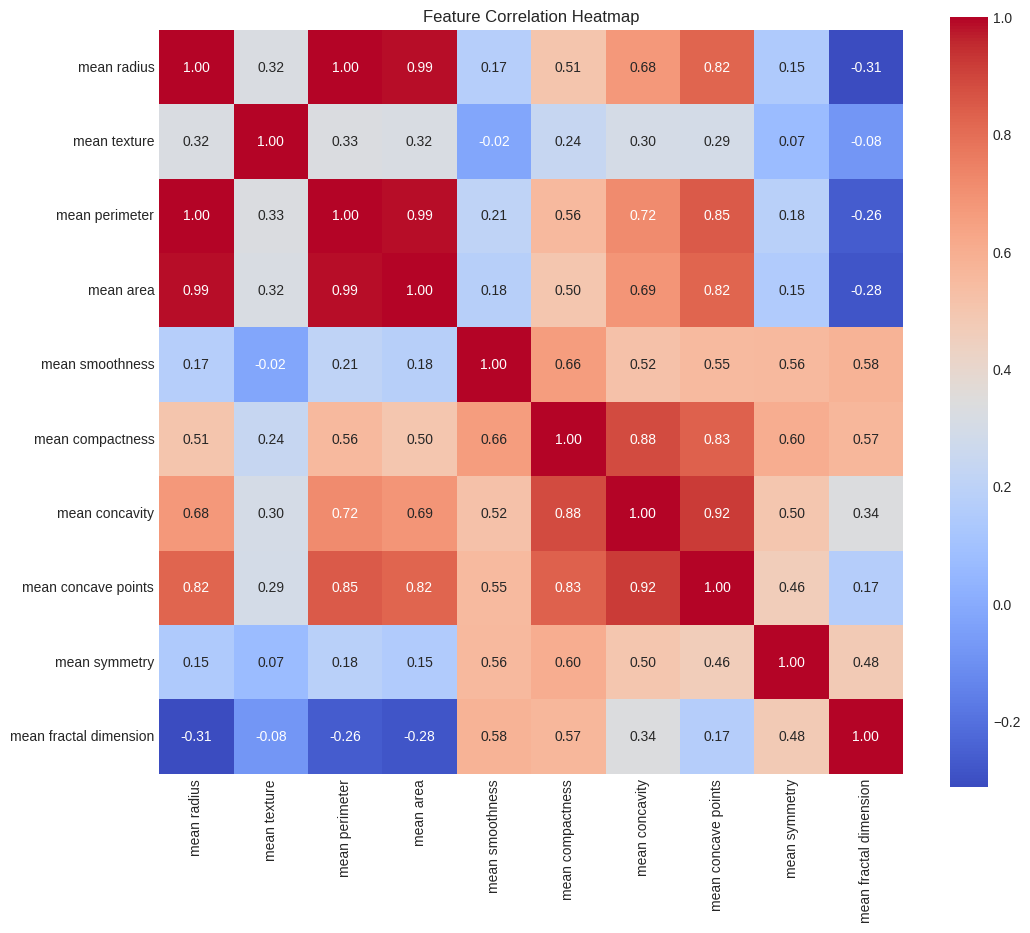

In [26]:
plt.figure(figsize=(12, 10))
corr = df[cancer.feature_names[:10]].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Feature Correlation Heatmap')
plt.show()

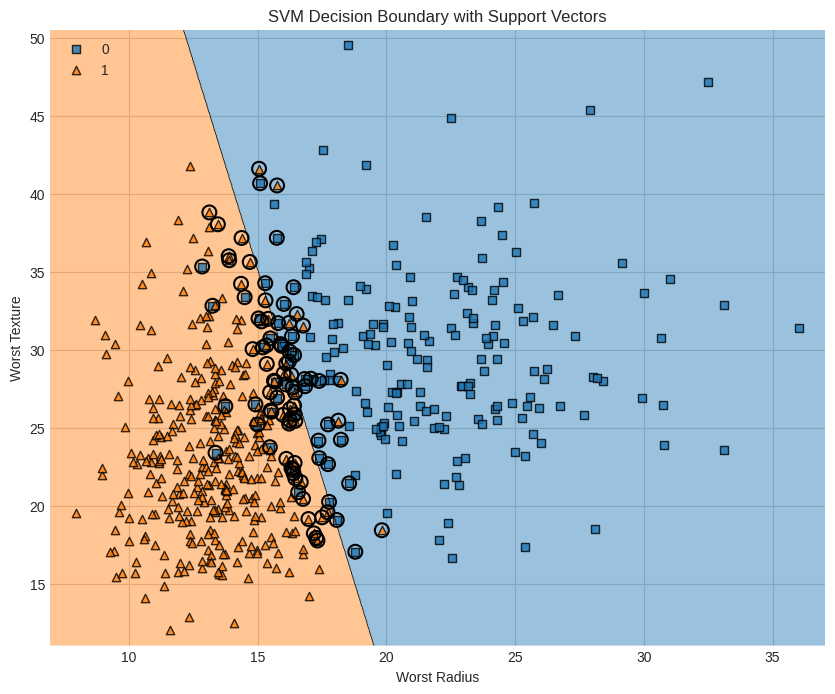

In [27]:
# Create a simplified 2D version using the two most informative features
X_2d = df[['worst radius', 'worst texture']].values

# Train a linear SVM on the simplified data
svm_2d = SVC(kernel='linear', C=1.0)
svm_2d.fit(X_2d, y)

# Plot the decision boundary and margin
plt.figure(figsize=(10, 8))
plot_decision_regions(X_2d, y, clf=svm_2d, legend=2)

# Highlight the support vectors
plt.scatter(svm_2d.support_vectors_[:, 0], svm_2d.support_vectors_[:, 1],
            s=100, facecolors='none', edgecolors='k', linewidths=1.5)

plt.xlabel('Worst Radius')
plt.ylabel('Worst Texture')
plt.title('SVM Decision Boundary with Support Vectors')
plt.show()

In [28]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train_scaled.shape)
print("Test set shape:", X_test_scaled.shape)

Training set shape: (398, 30)
Test set shape: (171, 30)


Linear SVM with C=0.001: Accuracy=0.9415, AUC=0.9924, mAP=0.9955
Linear SVM with C=0.01: Accuracy=0.9591, AUC=0.9946, mAP=0.9967
Linear SVM with C=0.1: Accuracy=0.9708, AUC=0.9934, mAP=0.9958
Linear SVM with C=1: Accuracy=0.9825, AUC=0.9947, mAP=0.9966
Linear SVM with C=10: Accuracy=0.9532, AUC=0.9911, mAP=0.9947
Linear SVM with C=100: Accuracy=0.9415, AUC=0.9796, mAP=0.9853


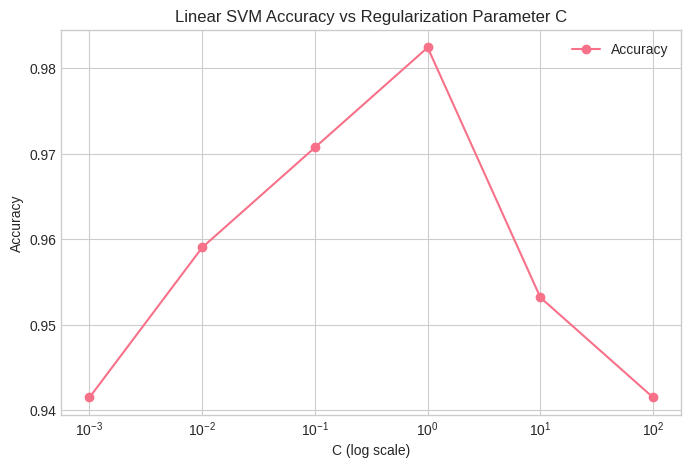

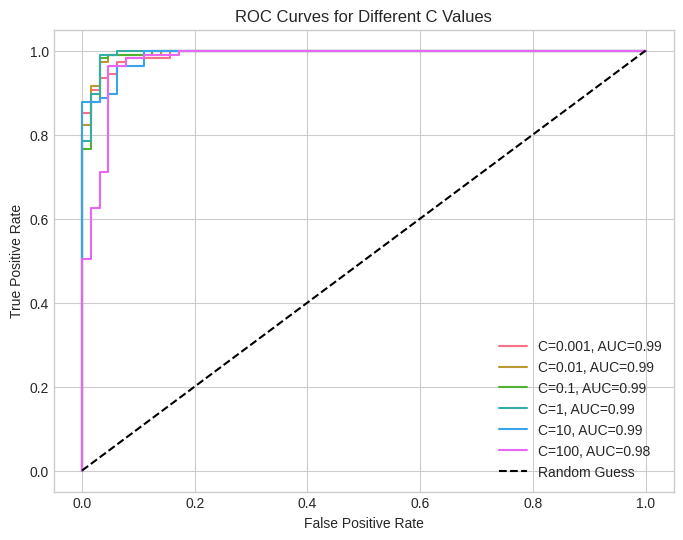

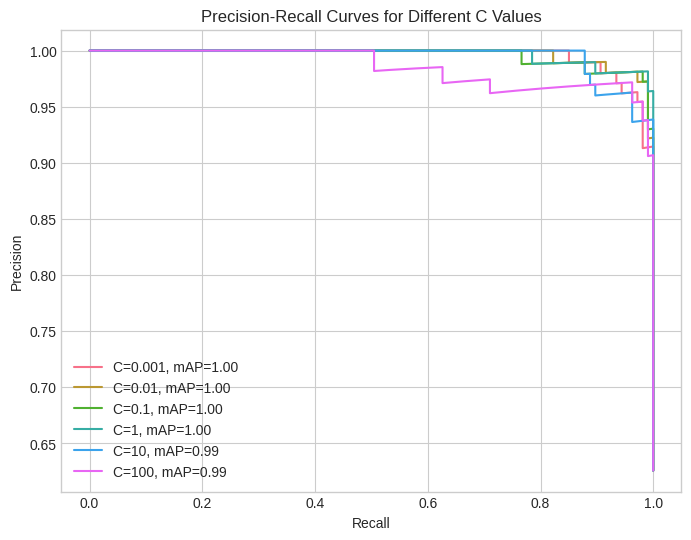

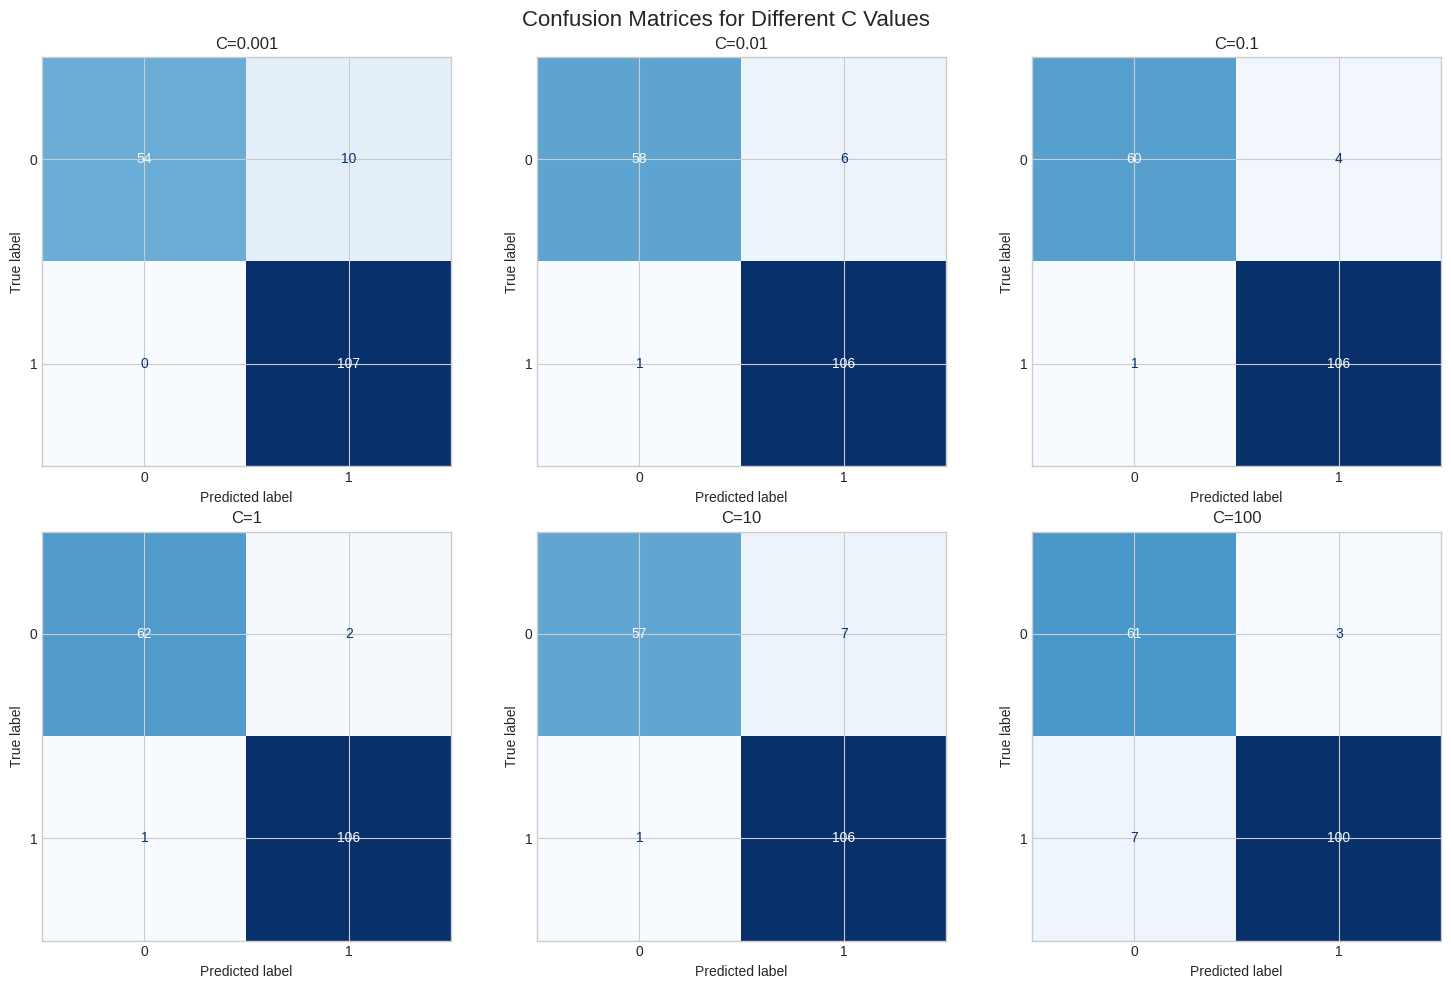

In [29]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Train linear SVMs with different C values
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
linear_svms = {}

for C in C_values:
    svm = SVC(kernel='linear', C=C, probability=True, random_state=42)
    svm.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = svm.predict(X_test_scaled)
    y_prob = svm.predict_proba(X_test_scaled)[:, 1]  # Probabilities for ROC & PR

    # Evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    avg_precision = average_precision_score(y_test, y_prob)

    linear_svms[C] = {
        'model': svm, 'accuracy': acc, 'confusion_matrix': cm,
        'fpr': fpr, 'tpr': tpr, 'roc_auc': roc_auc,
        'precision': precision, 'recall': recall, 'avg_precision': avg_precision
    }

    print(f"Linear SVM with C={C}: Accuracy={acc:.4f}, AUC={roc_auc:.4f}, mAP={avg_precision:.4f}")

# Plot Accuracy vs C
plt.figure(figsize=(8, 5))
plt.plot(C_values, [linear_svms[C]['accuracy'] for C in C_values], marker='o', label="Accuracy")
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('Accuracy')
plt.title('Linear SVM Accuracy vs Regularization Parameter C')
plt.grid(True)
plt.legend()
plt.show()

# Plot ROC Curves
plt.figure(figsize=(8, 6))
for C in C_values:
    plt.plot(linear_svms[C]['fpr'], linear_svms[C]['tpr'], label=f"C={C}, AUC={linear_svms[C]['roc_auc']:.2f}")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Different C Values")
plt.legend()
plt.show()

# Plot Precision-Recall Curves
plt.figure(figsize=(8, 6))
for C in C_values:
    plt.plot(linear_svms[C]['recall'], linear_svms[C]['precision'], label=f"C={C}, mAP={linear_svms[C]['avg_precision']:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves for Different C Values")
plt.legend()
plt.show()

# Display Confusion Matrices
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for idx, C in enumerate(C_values):
    ConfusionMatrixDisplay(linear_svms[C]['confusion_matrix']).plot(ax=axes[idx], values_format='d', cmap="Blues", colorbar=False)
    axes[idx].set_title(f"C={C}")
plt.suptitle("Confusion Matrices for Different C Values", fontsize=16)
plt.tight_layout()
plt.show()


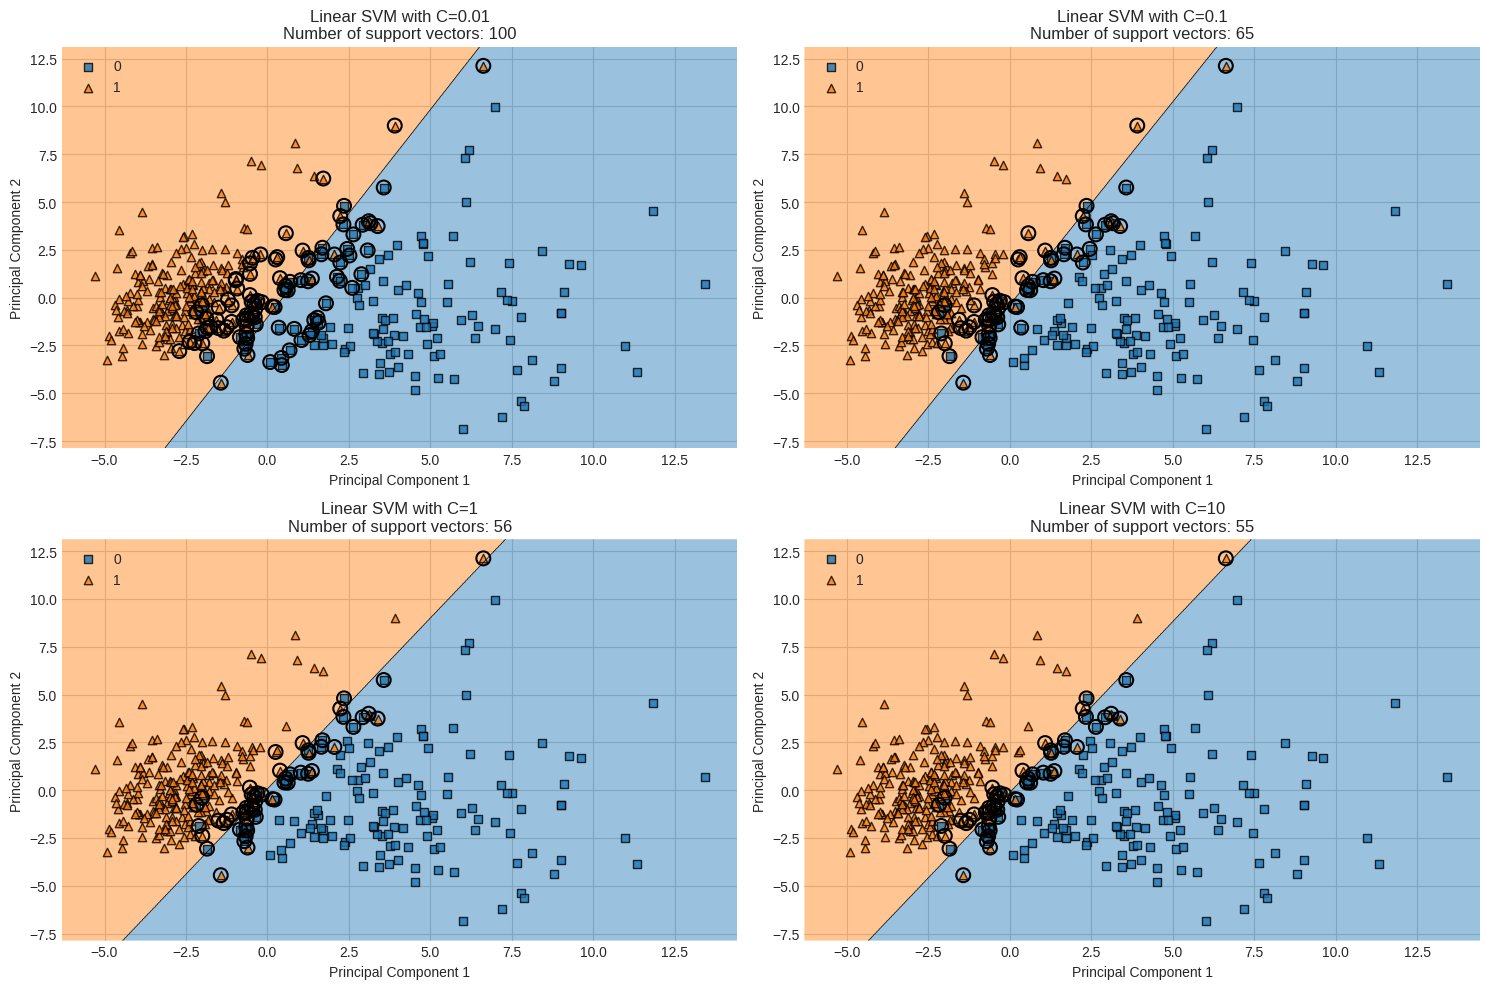

In [30]:
# Visualize the effect of C on the margin and support vectors
# We'll use PCA to reduce to 2D for visualization
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(15, 10))
for i, C in enumerate([0.01, 0.1, 1, 10]):
    # Train on PCA-transformed data
    svm = SVC(kernel='linear', C=C, random_state=42)
    svm.fit(X_train_pca, y_train)

    plt.subplot(2, 2, i+1)
    plot_decision_regions(X_train_pca, y_train, clf=svm, legend=2)
    plt.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
                s=100, facecolors='none', edgecolors='k', linewidths=1.5)
    plt.title(f'Linear SVM with C={C}\nNumber of support vectors: {len(svm.support_vectors_)}')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

**6.1 RBF (Radial Basis Function) Kernel**


RBF SVM with gamma=0.001: Accuracy = 0.9415
RBF SVM with gamma=0.01: Accuracy = 0.9649
RBF SVM with gamma=0.1: Accuracy = 0.9591
RBF SVM with gamma=1: Accuracy = 0.6257
RBF SVM with gamma=10: Accuracy = 0.6257
RBF SVM with gamma=100: Accuracy = 0.6257


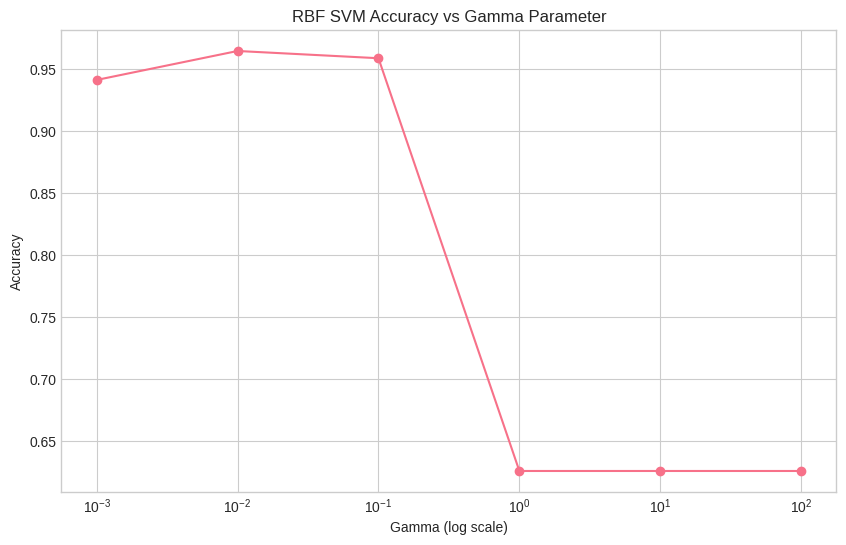

In [31]:
# Train RBF SVMs with different gamma values
gamma_values = [0.001, 0.01, 0.1, 1, 10, 100]
rbf_svms = {}

for gamma in gamma_values:
    svm = SVC(kernel='rbf', gamma=gamma, C=1, random_state=42)
    svm.fit(X_train_scaled, y_train)
    y_pred = svm.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    rbf_svms[gamma] = {'model': svm, 'accuracy': accuracy}
    print(f"RBF SVM with gamma={gamma}: Accuracy = {accuracy:.4f}")

# Plot accuracy vs gamma values
plt.figure(figsize=(10, 6))
plt.plot(gamma_values, [rbf_svms[g]['accuracy'] for g in gamma_values], marker='o')
plt.xscale('log')
plt.xlabel('Gamma (log scale)')
plt.ylabel('Accuracy')
plt.title('RBF SVM Accuracy vs Gamma Parameter')
plt.grid(True)
plt.show()

**6.2 Polynomial Kernel**

Polynomial SVM with degree=2: Accuracy = 0.7836
Polynomial SVM with degree=3: Accuracy = 0.8947
Polynomial SVM with degree=4: Accuracy = 0.7544
Polynomial SVM with degree=5: Accuracy = 0.8363
Polynomial SVM with degree=6: Accuracy = 0.7427


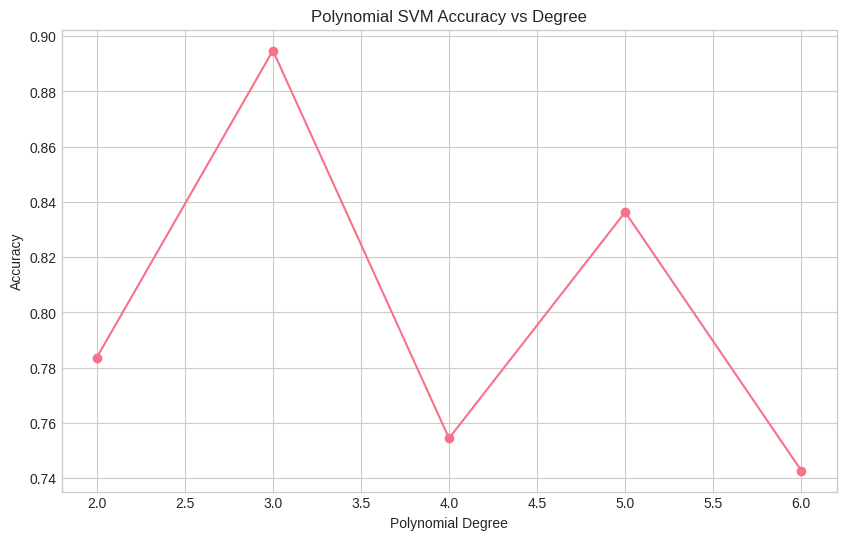

In [32]:
# Train polynomial SVMs with different degrees
degrees = [2, 3, 4, 5, 6]
poly_svms = {}

for degree in degrees:
    svm = SVC(kernel='poly', degree=degree, C=1, random_state=42)
    svm.fit(X_train_scaled, y_train)
    y_pred = svm.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    poly_svms[degree] = {'model': svm, 'accuracy': accuracy}
    print(f"Polynomial SVM with degree={degree}: Accuracy = {accuracy:.4f}")

# Plot accuracy vs polynomial degree
plt.figure(figsize=(10, 6))
plt.plot(degrees, [poly_svms[d]['accuracy'] for d in degrees], marker='o')
plt.xlabel('Polynomial Degree')
plt.ylabel('Accuracy')
plt.title('Polynomial SVM Accuracy vs Degree')
plt.grid(True)
plt.show()

**7. Kernel Comparison**

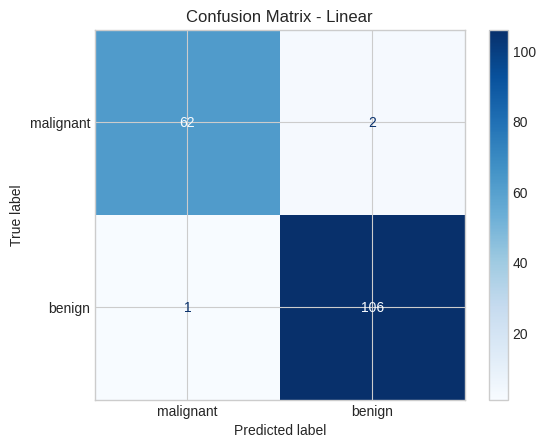

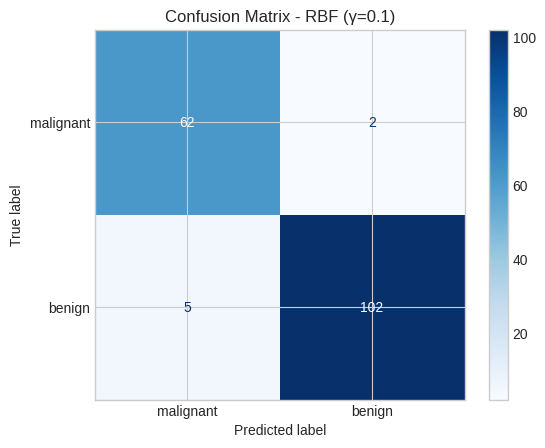

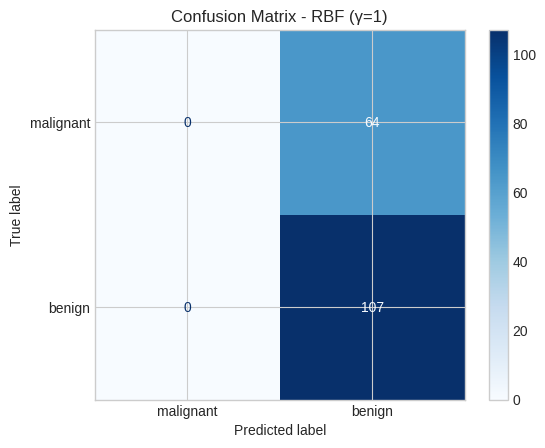

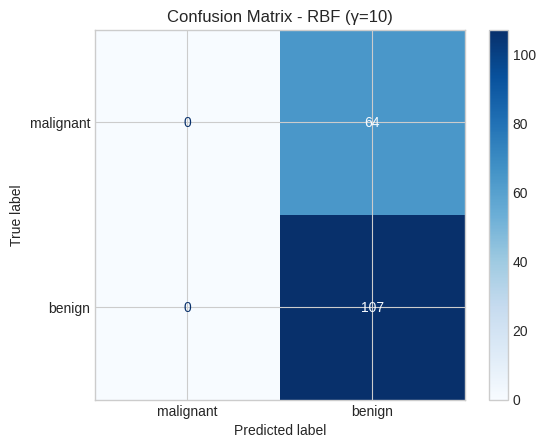

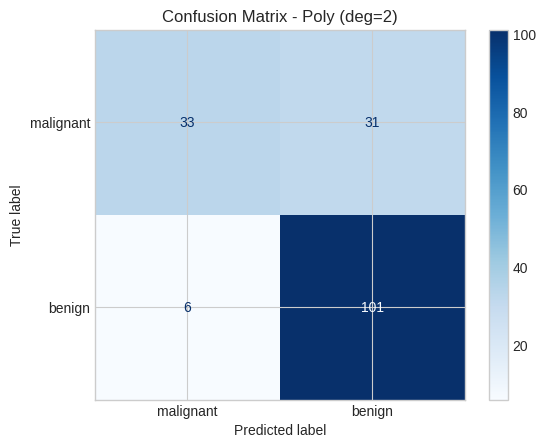

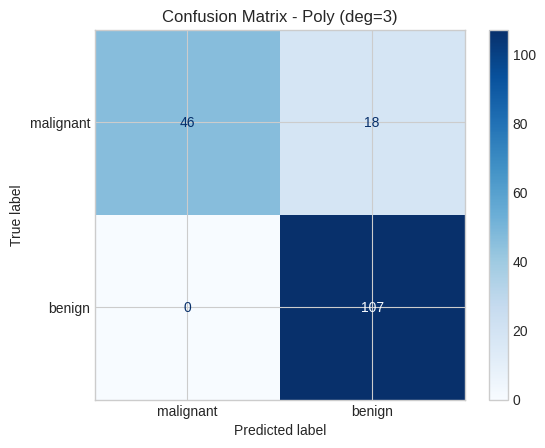

,Kernel,Accuracy,Precision,Recall,F1 Score,Support Vectors
0,Linear,0.982456,0.981481,0.990654,0.986047,31
1,RBF (γ=0.1),0.959064,0.980769,0.953271,0.966825,173
2,RBF (γ=1),0.625731,0.625731,1.000000,0.769784,398
3,RBF (γ=10),0.625731,0.625731,1.000000,0.769784,398
4,Poly (deg=2),0.783626,0.765152,0.943925,0.845188,213
5,Poly (deg=3),0.894737,0.856000,1.000000,0.922414,125


In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define the kernels to test
kernels = {
    'Linear': SVC(kernel='linear', random_state=42),
    'RBF (γ=0.1)': SVC(kernel='rbf', gamma=0.1, random_state=42),
    'RBF (γ=1)': SVC(kernel='rbf', gamma=1, random_state=42),
    'RBF (γ=10)': SVC(kernel='rbf', gamma=10, random_state=42),
    'Poly (deg=2)': SVC(kernel='poly', degree=2, random_state=42),
    'Poly (deg=3)': SVC(kernel='poly', degree=3, random_state=42)
}

# Train and evaluate each kernel
results = []
for name, model in kernels.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Append results
    results.append({
        'Kernel': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'Support Vectors': len(model.support_vectors_)
    })

    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
    disp.plot(cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

# Create results DataFrame
results_df = pd.DataFrame(results)
results_df


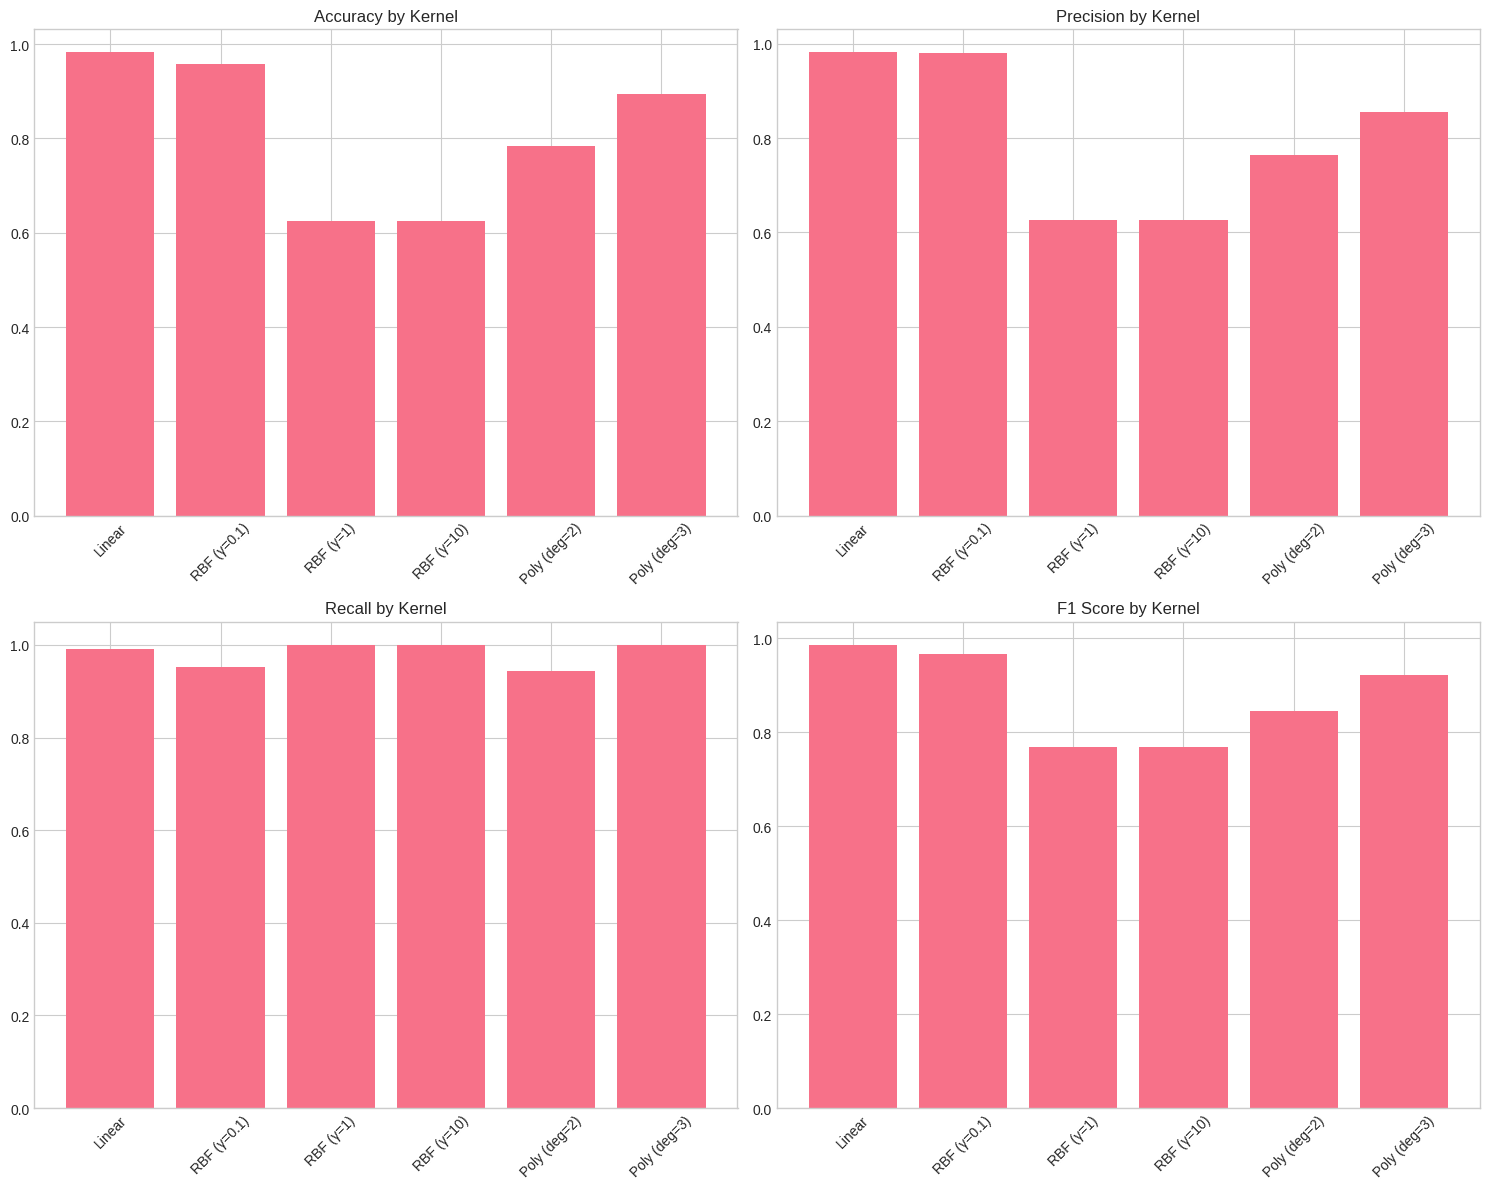

In [14]:
# Visualize kernel comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Accuracy
axes[0, 0].bar(results_df['Kernel'], results_df['Accuracy'])
axes[0, 0].set_title('Accuracy by Kernel')
axes[0, 0].tick_params(axis='x', rotation=45)

# Precision
axes[0, 1].bar(results_df['Kernel'], results_df['Precision'])
axes[0, 1].set_title('Precision by Kernel')
axes[0, 1].tick_params(axis='x', rotation=45)

# Recall
axes[1, 0].bar(results_df['Kernel'], results_df['Recall'])
axes[1, 0].set_title('Recall by Kernel')
axes[1, 0].tick_params(axis='x', rotation=45)

# F1 Score
axes[1, 1].bar(results_df['Kernel'], results_df['F1 Score'])
axes[1, 1].set_title('F1 Score by Kernel')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [15]:
# Define parameter grid for RBF kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1, 'scale', 'auto']
}

# Perform grid search
grid_search = GridSearchCV(
    SVC(kernel='rbf', random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_scaled, y_train)

# Print best parameters
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score: {:.4f}".format(grid_search.best_score_))

# Evaluate on test set
best_svm = grid_search.best_estimator_
y_pred = best_svm.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, y_pred)
print("Test set accuracy: {:.4f}".format(test_accuracy))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'C': 10, 'gamma': 0.001}
Best cross-validation score: 0.9799
Test set accuracy: 0.9708


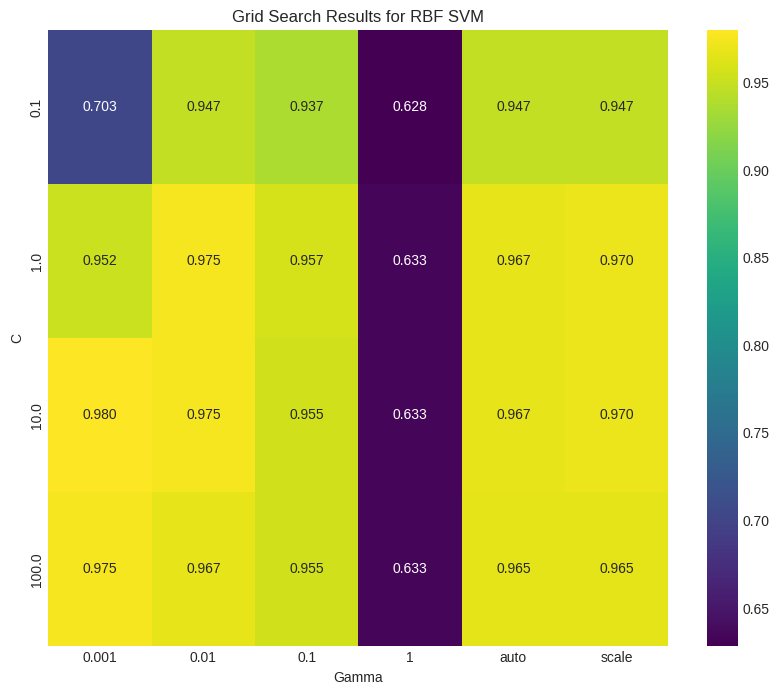

In [16]:
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot(index='param_C', columns='param_gamma', values='mean_test_score')

plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='viridis')
plt.title('Grid Search Results for RBF SVM')
plt.xlabel('Gamma')
plt.ylabel('C')
plt.show()

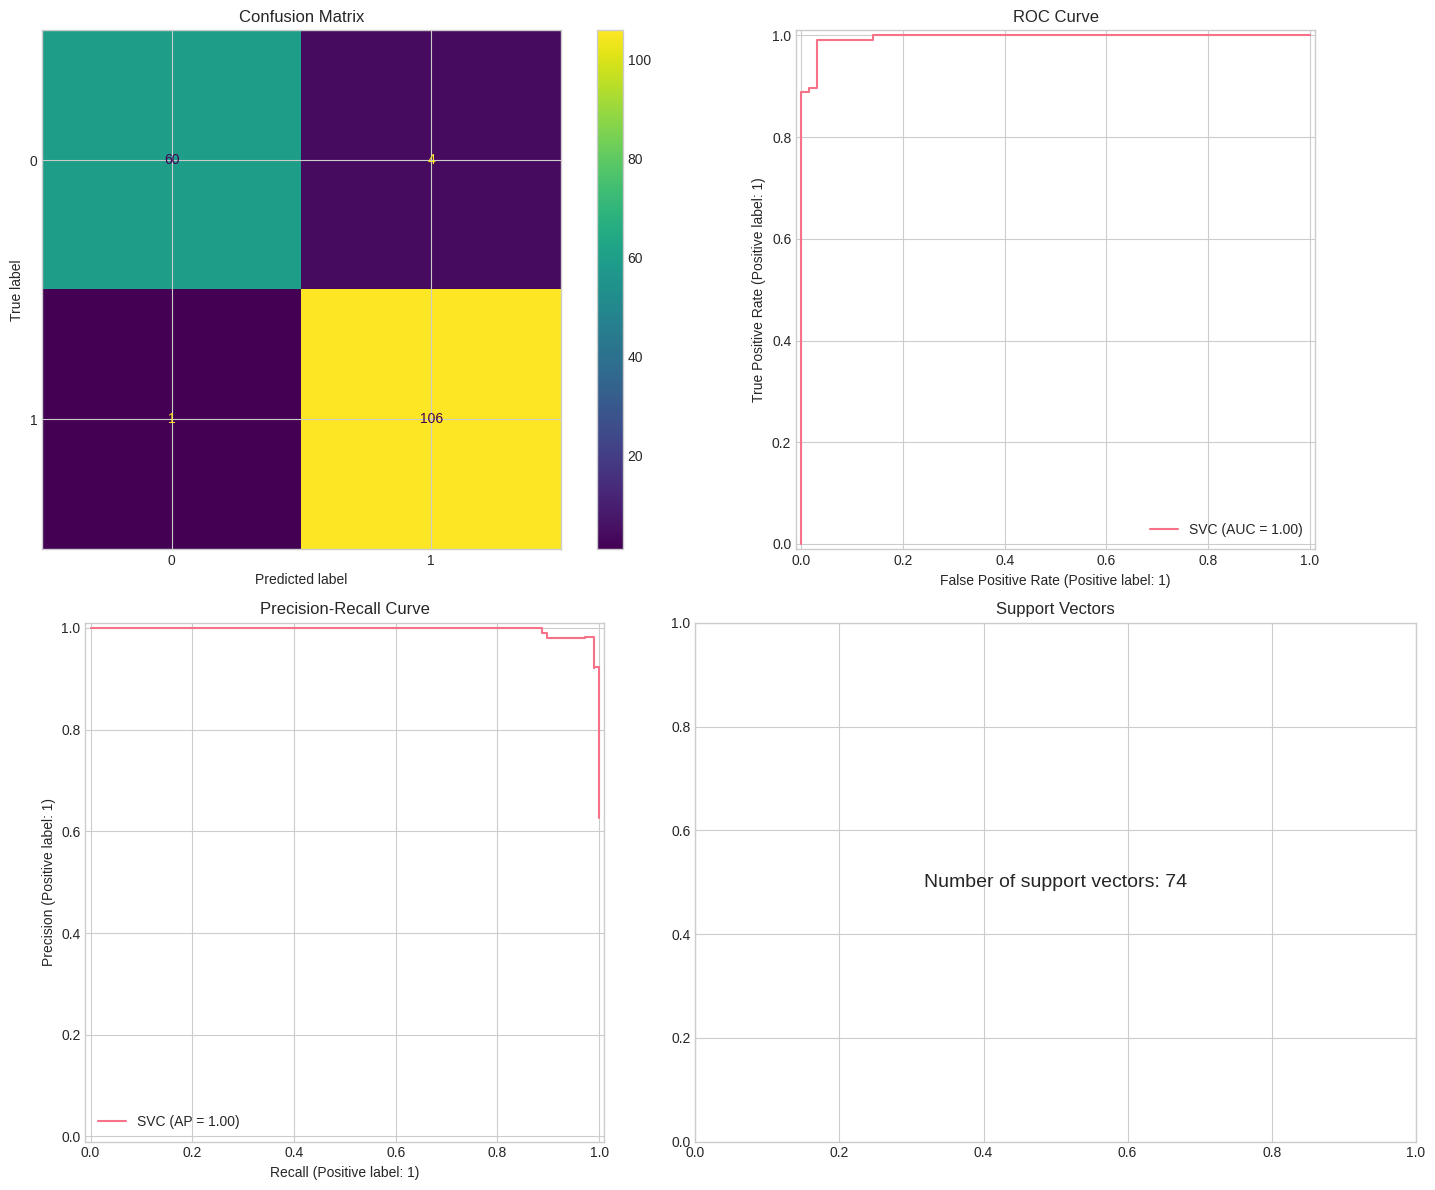

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.94      0.96        64
      benign       0.96      0.99      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

# Get predictions and decision scores
y_pred = best_svm.predict(X_test_scaled)
y_score = best_svm.decision_function(X_test_scaled)

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_scaled, y_test, ax=axes[0, 0])
axes[0, 0].set_title('Confusion Matrix')

# 2. ROC Curve
RocCurveDisplay.from_estimator(best_svm, X_test_scaled, y_test, ax=axes[0, 1])
axes[0, 1].set_title('ROC Curve')

# 3. Precision-Recall Curve
PrecisionRecallDisplay.from_estimator(best_svm, X_test_scaled, y_test, ax=axes[1, 0])
axes[1, 0].set_title('Precision-Recall Curve')

# 4. Feature Importance (for linear kernel)
if hasattr(best_svm, 'coef_'):
    coef = best_svm.coef_[0]
    indices = np.argsort(np.abs(coef))[::-1][:10]
    axes[1, 1].barh(range(len(indices)), coef[indices])
    axes[1, 1].set_yticks(range(len(indices)))
    axes[1, 1].set_yticklabels([cancer.feature_names[i] for i in indices])
    axes[1, 1].set_title('Top 10 Feature Importances')
else:
    # For non-linear kernels, we can't directly access feature importance
    # So we'll show the number of support vectors instead
    axes[1, 1].text(0.5, 0.5, f'Number of support vectors: {len(best_svm.support_vectors_)}',
                   ha='center', va='center', transform=axes[1, 1].transAxes, fontsize=14)
    axes[1, 1].set_title('Support Vectors')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

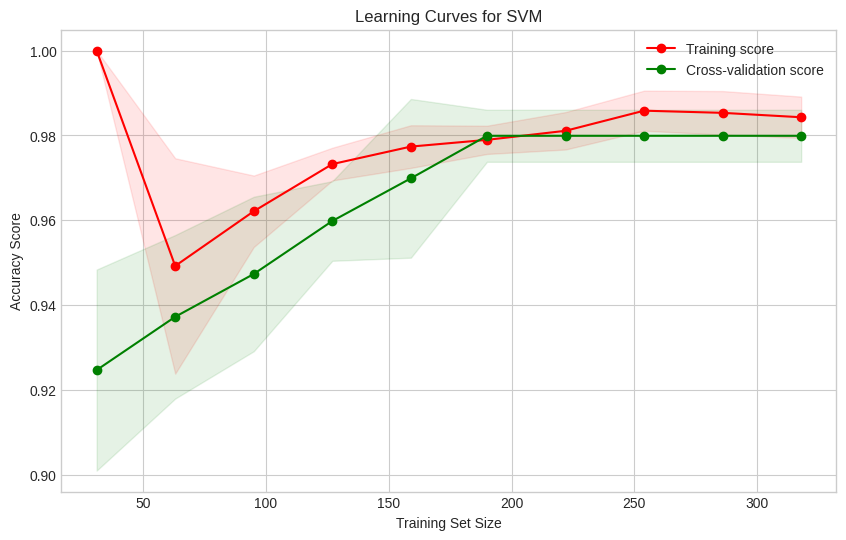

In [18]:
# Create learning curves
train_sizes, train_scores, test_scores = learning_curve(
    best_svm, X_train_scaled, y_train, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='accuracy', n_jobs=-1
)

# Calculate mean and standard deviation
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='r', label='Training score')
plt.plot(train_sizes, test_mean, 'o-', color='g', label='Cross-validation score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='r')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color='g')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy Score')
plt.title('Learning Curves for SVM')
plt.legend(loc='best')
plt.grid(True)
plt.show()

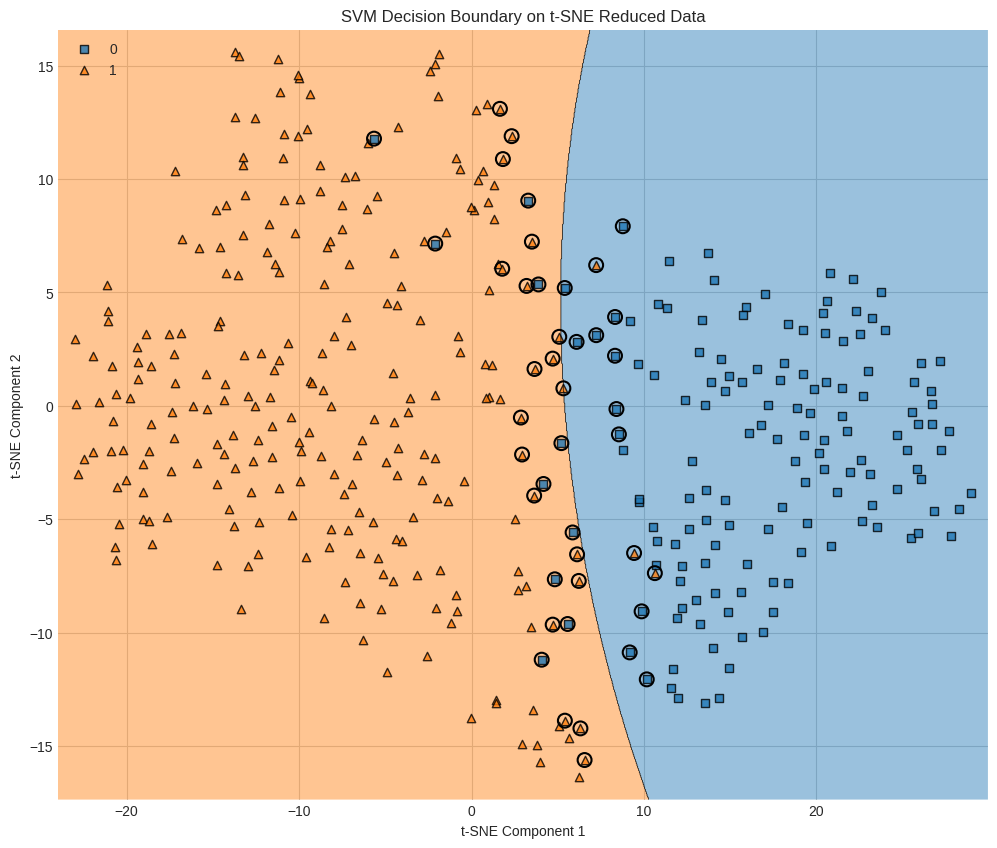

In [19]:
# Reduce dimensionality using t-SNE
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_train_scaled)

# Train SVM on t-SNE transformed data
svm_tsne = SVC(kernel='rbf', **grid_search.best_params_, random_state=42)
svm_tsne.fit(X_tsne, y_train)

# Plot decision boundary
plt.figure(figsize=(12, 10))
plot_decision_regions(X_tsne, y_train, clf=svm_tsne, legend=2)
plt.scatter(svm_tsne.support_vectors_[:, 0], svm_tsne.support_vectors_[:, 1],
            s=100, facecolors='none', edgecolors='k', linewidths=1.5)
plt.title('SVM Decision Boundary on t-SNE Reduced Data')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()

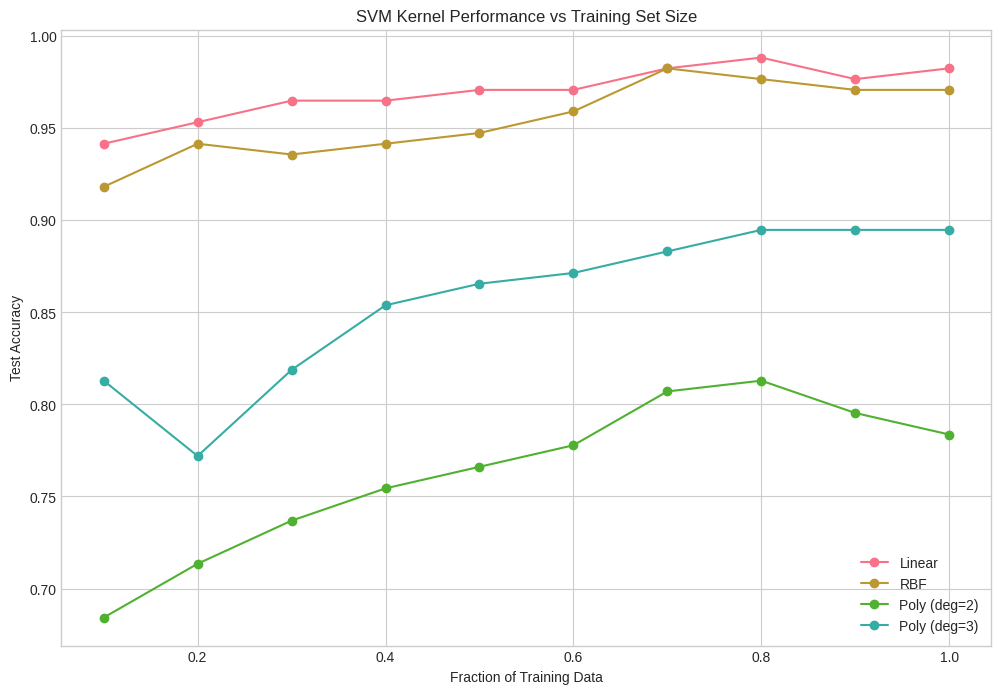

In [20]:
# Define training set fractions to test
train_sizes = np.linspace(0.1, 1.0, 10)
kernels_to_test = {
    'Linear': SVC(kernel='linear', random_state=42),
    'RBF': SVC(kernel='rbf', **grid_search.best_params_, random_state=42),
    'Poly (deg=2)': SVC(kernel='poly', degree=2, random_state=42),
    'Poly (deg=3)': SVC(kernel='poly', degree=3, random_state=42)
}

# Store results
results = {name: [] for name in kernels_to_test.keys()}

for size in train_sizes:
    # Calculate number of samples for this size
    n_samples = int(size * X_train_scaled.shape[0])
    X_subset = X_train_scaled[:n_samples]
    y_subset = y_train[:n_samples]

    for name, model in kernels_to_test.items():
        model.fit(X_subset, y_subset)
        score = model.score(X_test_scaled, y_test)
        results[name].append(score)

# Plot results
plt.figure(figsize=(12, 8))
for name, scores in results.items():
    plt.plot(train_sizes, scores, 'o-', label=name)

plt.xlabel('Fraction of Training Data')
plt.ylabel('Test Accuracy')
plt.title('SVM Kernel Performance vs Training Set Size')
plt.legend()
plt.grid(True)
plt.show()